# Homework 1: Word Embeddings

**Course:** NLP Fall 2026  
**Designer:** Kimia Vanaei

**Name:** Negin Moradi

**Environment:** Google Colab or Kaggle with a GPU

In this notebook, you will train word embeddings with Skip-gram and Negative Sampling (SGNS). You will implement the SGNS loss, cosine similarity, nearest-neighbor retrieval, similarity margins, and word analogies. The training loop and data preparation are already included so you can focus on the embedding methods and their results.

| Component | Points |
|:--|--:|
| Task 1: SGNS loss | 25 |
| Task 2: Cosine similarity | 15 |
| Task 3: Nearest neighbors | 10 |
| Task 4: Similarity margins | 10 |
| Task 5: Word analogies | 10 |
| Oral explanation (4 questions) | 30 |
| **Total** | **100** |

**What to submit:** your completed `.ipynb` file with its outputs and a screen recording of your oral explanation (around 5 minutes, no more than 10). There are no written questions to submit. You will be graded on your implementations and your explanation of the results.


## 0. Setup

We use PyTorch for training and `gensim-data` to download `text8` and GloVe. GPU is recommended for the training step.

In [1]:
import sys, subprocess, random, time
from collections import Counter

try:
    import gensim
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'gensim>=4.3,<5'])
    import gensim
import gensim.downloader as api
import smart_open
# Compatibility fix for older gensim-data versions.
if not hasattr(smart_open, 'smart_open'):
    smart_open.smart_open = smart_open.open

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
import matplotlib.pyplot as plt
from IPython.display import display
from gensim.test.utils import datapath

SEED = 0
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
set_seed()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'PyTorch {torch.__version__} | gensim {gensim.__version__} | device={device}')
if device.type != 'cuda':
    print('GPU recommended: the full training on CPU may take substantially longer.')

CFG = dict(min_count=5, max_vocab=20000, subsample_t=1e-4,
           window=5, dim=100, neg_k=5,
           batch=4096, lr=5e-3, epochs=4)

PyTorch 2.11.0+cu130 | gensim 4.4.0 | device=cuda


## 1. Data and context pairs

`text8` is a stream of about 17 million lowercased Wikipedia tokens. For each center word, Skip-gram uses nearby words as positive contexts. The code below reads the full corpus, builds a vocabulary, and forms the training pairs.

We keep source chunks separate when building context windows. Words outside the vocabulary are marked rather than removed, so their neighbors are not incorrectly joined together. Frequent words are also subsampled before pairs are generated.

`text8` does not contain sentence boundaries. The windows here are local token windows within the source chunks, not reconstructed sentences.

In [2]:
# Keep the original chunks separate when creating context windows.
text_chunks = [list(chunk) for chunk in api.load('text8')]
raw_tokens = sum(len(chunk) for chunk in text_chunks)
print(f'Text: {raw_tokens:,} tokens in {len(text_chunks):,} source chunks')

def build_vocab(chunks, min_count, max_vocab):
    counter = Counter(token for chunk in chunks for token in chunk)
    common = [(w, count) for w, count in counter.most_common(max_vocab)
              if count >= min_count]
    words = [w for w, count in common]
    return words, {w: i for i, w in enumerate(words)}, np.array([count for w, count in common], dtype=np.int64)

def encode_subsample_chunks(chunks, w2i, counts, threshold, seed=0):
    # Mark out-of-vocabulary words with -1 to preserve their positions.
    f = counts / counts.sum()
    p_keep = np.minimum(1., (np.sqrt(f / threshold) + 1.) * threshold / f)
    rng = np.random.default_rng(seed)
    result = []
    for chunk in chunks:
        ids = np.fromiter((w2i.get(w, -1) for w in chunk), dtype=np.int32, count=len(chunk))
        known = ids >= 0
        keep = np.ones(len(ids), dtype=bool)  # keep unknown positions
        keep[known] = rng.random(known.sum()) < p_keep[ids[known]]
        result.append(ids[keep])
    return result

def make_context_pairs(chunks, window, seed=0):
    # Pick a window radius for each center without crossing chunk boundaries.
    rng = np.random.default_rng(seed)
    centers, contexts = [], []
    for ids in chunks:
        ids = np.asarray(ids, dtype=np.int32)
        n = len(ids)
        if n < 2:
            continue
        radius = rng.integers(1, window + 1, size=n)
        for dist in range(1, min(window, n - 1) + 1):
            valid_r = (radius[:-dist] >= dist) & (ids[:-dist] >= 0) & (ids[dist:] >= 0)
            valid_l = (radius[dist:] >= dist) & (ids[dist:] >= 0) & (ids[:-dist] >= 0)
            if valid_r.any():
                centers.append(ids[:-dist][valid_r])
                contexts.append(ids[dist:][valid_r])
            if valid_l.any():
                centers.append(ids[dist:][valid_l])
                contexts.append(ids[:-dist][valid_l])
    if not centers:
        raise ValueError('No training pairs. Check token coverage and preprocessing.')
    return np.concatenate(centers).astype(np.int32), np.concatenate(contexts).astype(np.int32)

idx2word, word2idx, counts = build_vocab(text_chunks, CFG['min_count'], CFG['max_vocab'])
chunks_ids = encode_subsample_chunks(text_chunks, word2idx, counts, CFG['subsample_t'], SEED)
V = len(idx2word)
print(f'Vocabulary: {V:,} | retained known occurrences after subsampling: '
      f'{sum(np.count_nonzero(ids >= 0) for ids in chunks_ids):,}')

Text: 17,005,207 tokens in 1,701 source chunks
Vocabulary: 20,000 | retained known occurrences after subsampling: 8,612,910


In [3]:
# Check chunk boundaries and the positions of unknown words.
def test_preprocessing_boundaries():
    # The last word of one chunk must not pair with the next chunk.
    a, b = make_context_pairs([np.array([0, 1]), np.array([2, 3])], window=1, seed=1)
    pairs = set(zip(a.tolist(), b.tolist()))
    assert pairs == {(0, 1), (1, 0), (2, 3), (3, 2)}, pairs
    # Skipping an unknown word must not make its neighbors adjacent.
    # No valid pairs should raise an error.
    try:
        make_context_pairs([np.array([0, -1, 1])], window=1, seed=1)
    except ValueError:
        pass
    else:
        raise AssertionError('unknown token incorrectly collapsed')
    # A window of two can still connect words two positions apart.
    aa, bb = make_context_pairs([np.array([0, -1, 1, 2])], window=2, seed=4)
    assert all(v >= 0 for v in aa) and all(v >= 0 for v in bb)
    print('✓ chunk boundary and unknown-position tests passed')
test_preprocessing_boundaries()

✓ chunk boundary and unknown-position tests passed


In [4]:
# Report corpus size and the effect of vocabulary filtering and subsampling.
display(pd.DataFrame([
    ('Original text8 words', f'{raw_tokens:,}'),
    ('Input chunks', f'{len(text_chunks):,}'),
    ('Vocabulary types', f'{V:,}'),
    ('Retained known word occurrences', f'{sum(np.count_nonzero(x >= 0) for x in chunks_ids):,}'),
], columns=['Data stage', 'Count']).set_index('Data stage'))

,Count
Data stage,
Original text8 words,"17,005,207"
Input chunks,"1,701"
Vocabulary types,"20,000"
Retained known word occurrences,"8,612,910"


## 2. Task 1: SGNS loss (25 points)

For a center word $c$, an observed context word $o$, and $K$ sampled negative contexts $n_i$, the batch loss is

$$
\mathcal L = -\frac{1}{B}\sum_{j=1}^{B}
\left[\log\sigma(v_{c_j}^{\top}u_{o_j})
+\sum_{i=1}^{K}\log\sigma(-v_{c_j}^{\top}u_{n_{j,i}})\right].
$$

Here $v$ refers to a **center embedding** and $u$ to a **context embedding**. The negative sampling distribution is proportional to $\mathrm{count}(w)^{0.75}$.

Complete `sgns_loss(center, pos, neg)` in the next cell. The input shapes are `(B, D)`, `(B, D)`, and `(B, K, D)`.  
Return one scalar: the mean loss over the batch. Use `F.logsigmoid` for both terms and sum the negative terms for each example. PyTorch will handle the gradients.

In [5]:
def sgns_loss(center, pos, neg):
    """center (B,D), pos (B,D), neg (B,K,D) -> scalar loss."""
    # TODO: implement this function according to the task instructions.
    positive = (center * pos).sum(dim=1) # calculating the dot product for each positive pair
    negative = (center.unsqueeze(1) * neg).sum(dim=2) # calculating the dot product for each negative pair, adding another dimention to center

    loss = -(F.logsigmoid(positive) + F.logsigmoid(-negative).sum(dim=1))
    
    return loss.mean()

In [6]:
# Check the loss value, numerical stability, and gradients.
def test_sgns():
    a = torch.tensor([[1., 0.]]); p = torch.tensor([[1., 0.]]); n = torch.tensor([[[0., 1.]]])
    assert abs(sgns_loss(a, p, n).item() - 1.0064089) < 1e-4
    a = torch.tensor([[200., 0.]]); p = torch.tensor([[-1., 0.]]); n = torch.tensor([[[1., 0.]]])
    assert abs(sgns_loss(a, p, n).item() - 400.) < 1e-3
    gen = torch.Generator().manual_seed(7)
    a = torch.randn(2, 3, dtype=torch.double, generator=gen, requires_grad=True)
    p = torch.randn(2, 3, dtype=torch.double, generator=gen, requires_grad=True)
    n = torch.randn(2, 2, 3, dtype=torch.double, generator=gen, requires_grad=True)
    ps = (a * p).sum(-1); ns = torch.bmm(n, a[..., None]).squeeze(-1)
    ref = (F.binary_cross_entropy_with_logits(ps, torch.ones_like(ps), reduction='none')
           + F.binary_cross_entropy_with_logits(ns, torch.zeros_like(ns), reduction='none').sum(-1)).mean()
    got = sgns_loss(a, p, n)
    assert torch.allclose(got, ref, atol=1e-11)
    assert torch.autograd.gradcheck(sgns_loss, (a, p, n), eps=1e-6, atol=1e-4)
    print('✓ SGNS value / reference / gradient tests passed')
test_sgns()

✓ SGNS value / reference / gradient tests passed


### Training the model

The next cell trains the SGNS model using the training pairs created above. It uses Adam and a learning rate that decreases during training. The learned **center embeddings** are stored in `E_mine` for the rest of the notebook.
The full corpus is loaded, but vocabulary filtering and subsampling reduce the number of tokens used to make training pairs.

In [7]:
class SkipGram(nn.Module):
    def __init__(self, vocab_size, dim):
        super().__init__()
        self.in_embed = nn.Embedding(vocab_size, dim)
        self.out_embed = nn.Embedding(vocab_size, dim)
        nn.init.uniform_(self.in_embed.weight, -0.5 / dim, 0.5 / dim)
        nn.init.zeros_(self.out_embed.weight)

def train_sgns(encoded_chunks, counts, cfg, seed=0):
    set_seed(seed)
    c_np, o_np = make_context_pairs(encoded_chunks, cfg['window'], seed)
    train_sgns.pair_count = len(c_np)
    print(f'Positive center/context pairs: {len(c_np):,}')
    centers = torch.from_numpy(c_np).to(device)
    contexts = torch.from_numpy(o_np).to(device)
    del c_np, o_np
    noise = torch.as_tensor(counts.astype(np.float64)**0.75, dtype=torch.float32, device=device)
    noise /= noise.sum()
    model = SkipGram(len(counts), cfg['dim']).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg['lr'])
    num_batches = (len(centers) + cfg['batch'] - 1) // cfg['batch']
    max_steps = cfg['epochs'] * num_batches
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer, lambda step: max(.05, 1 - step / max_steps))
    losses, steps, start = [], 0, time.perf_counter()
    for epoch in range(cfg['epochs']):
        perm = torch.randperm(len(centers), device=device)
        epoch_losses = []
        for start_idx in range(0, len(centers), cfg['batch']):
            indices = perm[start_idx:start_idx + cfg['batch']]
            c = centers[indices].long()
            o = contexts[indices].long()
            neg = torch.multinomial(noise, len(c) * cfg['neg_k'], replacement=True).reshape(len(c), cfg['neg_k'])
            loss = sgns_loss(model.in_embed(c), model.out_embed(o), model.out_embed(neg))
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step(); scheduler.step()
            epoch_losses.append(loss.item())
            if steps % 50 == 0:
                losses.append((steps, float(loss.item())))
            steps += 1
        print(f'epoch {epoch+1}/{cfg["epochs"]}: mean loss={np.mean(epoch_losses):.3f} | '
              f'elapsed={time.perf_counter()-start:.0f}s')
    return model, losses

model, losses = train_sgns(chunks_ids, counts, CFG, SEED)
E_mine = model.in_embed.weight.detach().cpu()

Positive center/context pairs: 46,742,964
epoch 1/4: mean loss=2.363 | elapsed=36s
epoch 2/4: mean loss=2.286 | elapsed=73s
epoch 3/4: mean loss=2.254 | elapsed=109s
epoch 4/4: mean loss=2.224 | elapsed=144s


### Check the training loss

The plot shows the loss recorded during training. The dashed line is a reference for a model that assigns the **same score to every positive and negative pair**.

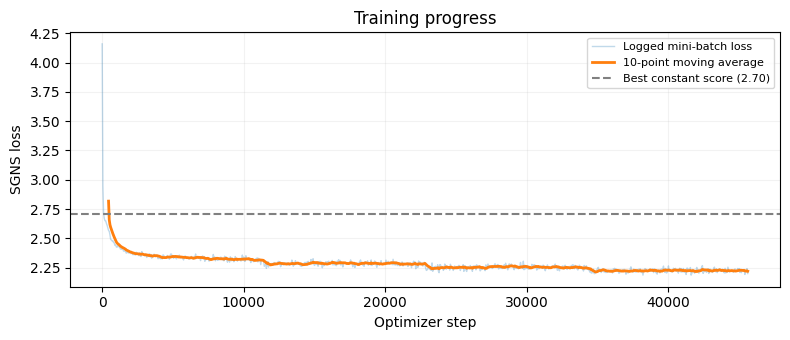

Positive pairs: 46,742,964 | epochs: 4 | recent logged loss: 2.220


In [8]:
K = CFG['neg_k']
constant_score_baseline = (K + 1) * np.log(K + 1) - K * np.log(K)
logged_steps = np.array([s for s, _ in losses])
logged_loss = np.array([v for _, v in losses])
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(logged_steps, logged_loss, alpha=0.28, lw=1, label='Logged mini-batch loss')
if len(logged_loss) >= 10:
    moving_avg = np.convolve(logged_loss, np.ones(10) / 10, mode='valid')
    ax.plot(logged_steps[9:], moving_avg, linewidth=2, label='10-point moving average')
ax.axhline(constant_score_baseline, color='gray', linestyle='--',
           label=f'Best constant score ({constant_score_baseline:.2f})')
ax.set(xlabel='Optimizer step', ylabel='SGNS loss', title='Training progress')
ax.legend(fontsize=8)
ax.grid(alpha=0.16)
plt.tight_layout()
plt.show()
print(f'Positive pairs: {train_sgns.pair_count:,} | epochs: {CFG["epochs"]} | '
      f'recent logged loss: {logged_loss[-min(10, len(logged_loss)):].mean():.3f}')

## 3. Task 2: Cosine similarity (15 points)

Cosine similarity measures the angle between two vectors:

$$
\cos(x,y)=\frac{x^{\top}y}{\|x\|_2\|y\|_2}.
$$

Complete `cosine_similarity_matrix(A, B)`. Given matrices of shape `(n, d)` and `(m, d)`, return the `(n, m)` matrix of pairwise cosine similarities.

Use `F.normalize` or clamp the norms to a small epsilon so zero vectors give zero similarities.


In [9]:
def cosine_similarity_matrix(A, B):
    """A (n,d), B (m,d) -> (n,m) cosine similarity matrix."""
    # TODO: implement this function according to the task instructions.
    A_normed = F.normalize(A, p=2, dim=1)
    B_normed = F.normalize(B, p=2, dim=1)
    
    return A_normed @ B_normed.T # performing matrix multiplication

In [10]:
def test_cosine_similarity():
    A = torch.tensor([[1., 0.], [0., 2.], [0., 0.]])
    B = torch.tensor([[3., 0.], [0., -1.], [1., 1.]])
    expected = torch.tensor([[1., 0., 2**-0.5], [0., -1., 2**-0.5], [0., 0., 0.]])
    got = cosine_similarity_matrix(A, B)
    assert got.shape == (3, 3) and torch.allclose(got, expected, atol=1e-5)
    X = torch.randn((6, 8), generator=torch.Generator().manual_seed(4))
    reference = torch.stack([F.cosine_similarity(x[None], X, dim=-1) for x in X])
    assert torch.allclose(cosine_similarity_matrix(X, X), reference, atol=1e-5)
    print('✓ cosine similarity passed')
test_cosine_similarity()

✓ cosine similarity passed


## 4. Task 3: Nearest neighbors (10 points)

Complete `nearest_neighbors(word, E, word2idx, idx2word, k=10)`.

Compute the cosine similarity between the query word and every word in `E`. Exclude the query word itself, then return the `k` highest-scoring results as a list of `(word, similarity)` tuples, ordered from highest to lowest similarity.

A close neighbor may share a topic or usage pattern with the query without being its synonym.

In [11]:
def nearest_neighbors(word, E, word2idx, idx2word, k=10):
    """Top-k (word, cosine) neighbors, excluding the query."""
    # TODO: implement this function according to the task instructions.
    word_id = word2idx[word] # query word's ID
    turn = E[word_id].unsqueeze(0)
    
    check = cosine_similarity_matrix(turn, E).squeeze(0)

    check[word_id] = float('-inf') # excludes the query word by overwriting its own score with minus infinity

    top_values, top_indices = torch.topk(check, k)
    return [(idx2word[i], s) for i, s in zip(top_indices, top_values)]

In [12]:
def test_neighbors():
    names = ['target', 'related', 'orthogonal', 'opposite']
    vectors = torch.tensor([[1.,0.],[2.,0.],[0.,1.],[-1.,0.]])
    ix = {w:i for i,w in enumerate(names)}
    got = nearest_neighbors('target', vectors, ix, names, k=3)
    assert [w for w,_ in got] == ['related', 'orthogonal', 'opposite'], got
    assert abs(got[0][1] - 1) < 1e-6
    assert 'target' not in [w for w,_ in got]
    print('✓ nearest neighbors passed')
test_neighbors()

✓ nearest neighbors passed


### Look at the nearest neighbors

The following table shows the five closest words for several queries, together with their cosine similarities. Look for both sensible associations and less obvious matches. You will discuss these results in the oral questions.

In [13]:
NEIGHBOR_QUERIES = ['france', 'computer', 'music', 'water']
neighbor_rows = []
for query in NEIGHBOR_QUERIES:
    if query not in word2idx:
        continue
    for rank, (word, score) in enumerate(
            nearest_neighbors(query, E_mine, word2idx, idx2word, k=5), start=1):
        neighbor_rows.append({'Query': query, 'Rank': rank,
                              'Neighbor': word, 'Cosine': score})
neighbor_report = pd.DataFrame(neighbor_rows)
display(neighbor_report.style.format({'Cosine': '{:.3f}'}).hide(axis='index'))

Query,Rank,Neighbor,Cosine
france,1,belgium,0.766
france,2,netherlands,0.734
france,3,italy,0.721
france,4,spain,0.721
france,5,switzerland,0.678
computer,1,computers,0.785
computer,2,hardware,0.721
computer,3,computing,0.706
computer,4,graphics,0.652
computer,5,software,0.647


## 5. Comparison with pretrained GloVe

The table below shows nearest neighbors from our SGNS model and pretrained 100-dimensional GloVe. The candidate words are restricted to the vocabulary shared by the two models.

GloVe was trained on a much larger dataset. We use it as a reference, not for a fair algorithm comparison. Focus on the retrieved words rather than comparing cosine scores directly.

In [14]:
glove = api.load('glove-wiki-gigaword-100')
shared = [word for word in idx2word if word in glove.key_to_index]
assert len(shared) > 1000, 'Insufficient shared vocabulary.'
sh_w2i = {word: i for i, word in enumerate(shared)}
E_mine_sh = E_mine[[word2idx[word] for word in shared]]
E_glove_sh = torch.tensor(np.stack([glove[word] for word in shared]), dtype=torch.float32)
print(f'Shared candidate vocabulary: {len(shared):,} word types')

# Compare the retrieved words rather than cosine values across models.
reference_rows = []
for query in ['computer', 'water', 'java']:
    if query not in sh_w2i:
        continue
    reference_rows.append({
        'Query': query,
        'Our SGNS (top 4)': ', '.join(w for w, _ in nearest_neighbors(
            query, E_mine_sh, sh_w2i, shared, k=4)),
        'Pretrained GloVe (top 4)': ', '.join(w for w, _ in nearest_neighbors(
            query, E_glove_sh, sh_w2i, shared, k=4))
    })
display(pd.DataFrame(reference_rows).style.hide(axis='index'))

Shared candidate vocabulary: 19,939 word types


Query,Our SGNS (top 4),Pretrained GloVe (top 4)
computer,"computers, hardware, computing, graphics","computers, software, technology, pc"
water,"salt, groundwater, sewage, dioxide","natural, dry, salt, clean"
java,"lisp, emacs, scripting, applet","sumatra, borneo, remote, unix"


## 6. Task 4: Similarity margins (10 points)

For each triplet `(anchor, candidate_A, candidate_B)`, calculate

$$
\Delta_i=\cos(v_{a_i},v_{A_i})-\cos(v_{a_i},v_{B_i}).
$$

A positive margin means candidate A is closer to the anchor. A negative margin means candidate B is closer.

Complete `similarity_margins(E, anchor_ids, candidate_a_ids, candidate_b_ids)` and return a 1D tensor with one margin per triplet. `E` has shape `(vocab_size, dim)`. All three index tensors are one-dimensional and have the same length.

**Use tensor operations rather than a Python loop over the triplets.** You may reuse your cosine implementation or `F.normalize`. We will use these margins to compare near-synonyms with antonyms.

In [15]:
def similarity_margins(E, anchor_ids, candidate_a_ids, candidate_b_ids):
    """Return one cosine(A, anchor)-cosine(B, anchor) margin per triplet; shape (T,)."""
    # TODO: implement this function according to the task instructions.
    anchor = F.normalize(E[anchor_ids], p=2, dim=1) # fetching all anchor vectors in one step

    candidate_a = F.normalize(E[candidate_a_ids], p=2, dim=1)
    candidate_b = F.normalize(E[candidate_b_ids], p=2, dim=1)

    cos_a = (anchor * candidate_a).sum(dim=1)
    cos_b = (anchor * candidate_b).sum(dim=1)
    
    return cos_a - cos_b

In [16]:
def test_similarity_margins():
    E = torch.tensor([[1.,0.],[.8,.6],[-1.,0.],[0.,1.],[0.,0.]],dtype=torch.float32)
    a = torch.tensor([0,0,0]); pos = torch.tensor([1,2,4]); neg = torch.tensor([2,3,3])
    out = similarity_margins(E,a,pos,neg)
    assert out.shape == (3,), f'Expected shape (3,), got {out.shape}'
    torch.testing.assert_close(out,torch.tensor([1.8,-1.,0.]),atol=1e-6,rtol=1e-6)
    print('✓ Pairwise margin values, signs, and zero-vector stability passed')
test_similarity_margins()

✓ Pairwise margin values, signs, and zero-vector stability passed


## 7. Experiment A: Synonyms and antonyms

In this experiment, candidate A is a near-synonym and candidate B is an antonym. Your function computes

$$
\Delta=\cos(\text{anchor},\text{synonym})
-\cos(\text{anchor},\text{antonym}).
$$

A negative margin means the antonym is closer to the anchor than the near-synonym. The chart reports margins for a small, hand-selected set of words. The table underneath includes the individual cosine values for a few examples.

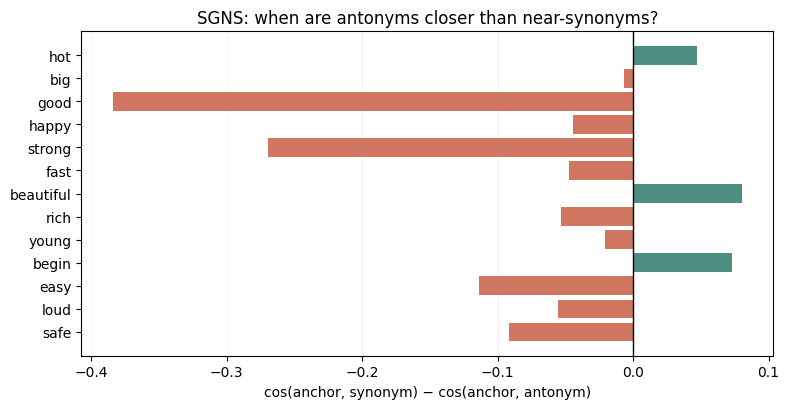

Probe coverage: 13/13 | synonym ranked higher: 23% | antonym ranked above unrelated: 100%


Anchor,Synonym,Antonym,"Cos(anchor, synonym)","Cos(anchor, antonym)","Cos(anchor, unrelated)",Margin
good,great,bad,0.366,0.750,0.035,-0.384
hot,warm,cold,0.638,0.591,0.068,0.047
fast,quick,slow,0.587,0.635,-0.057,-0.048
easy,simple,difficult,0.590,0.704,0.133,-0.114


In [17]:
PAIR_PROBES = [
    ('hot', 'warm', 'cold', 'computer'),
    ('big', 'large', 'small', 'ocean'),
    ('good', 'great', 'bad', 'river'),
    ('happy', 'glad', 'sad', 'machine'),
    ('strong', 'powerful', 'weak', 'january'),
    ('fast', 'quick', 'slow', 'politics'),
    ('beautiful', 'pretty', 'ugly', 'computer'),
    ('rich', 'wealthy', 'poor', 'mountain'),
    ('young', 'youthful', 'old', 'software'),
    ('begin', 'start', 'end', 'guitar'),
    ('easy', 'simple', 'difficult', 'biology'),
    ('loud', 'noisy', 'quiet', 'history'),
    ('safe', 'secure', 'dangerous', 'football'),
]
valid_probes = [p for p in PAIR_PROBES if all(w in word2idx for w in p)]
assert len(valid_probes) >= 8, 'Too few probes are in the trained vocabulary.'
ids_a = torch.tensor([word2idx[p[0]] for p in valid_probes])
ids_s = torch.tensor([word2idx[p[1]] for p in valid_probes])
ids_t = torch.tensor([word2idx[p[2]] for p in valid_probes])
ids_u = torch.tensor([word2idx[p[3]] for p in valid_probes])

margins = similarity_margins(E_mine, ids_a, ids_s, ids_t)
anti_unrelated = similarity_margins(E_mine, ids_a, ids_t, ids_u)
normalized = F.normalize(E_mine, dim=1, eps=1e-12)
def paired_cosine(x, y):
    return (normalized[x] * normalized[y]).sum(dim=1)

probe_df = pd.DataFrame({
    'Anchor': [p[0] for p in valid_probes],
    'Synonym': [p[1] for p in valid_probes],
    'Antonym': [p[2] for p in valid_probes],
    'Cos(anchor, synonym)': paired_cosine(ids_a, ids_s).numpy(),
    'Cos(anchor, antonym)': paired_cosine(ids_a, ids_t).numpy(),
    'Cos(anchor, unrelated)': paired_cosine(ids_a, ids_u).numpy(),
    'Margin': margins.numpy(),
})
fig, ax = plt.subplots(figsize=(8, 4.2))
order = np.arange(len(probe_df))
ax.barh(order, probe_df['Margin'], color=['#d17660' if v < 0 else '#4d8e82' for v in probe_df['Margin']])
ax.set_yticks(order, probe_df['Anchor'])
ax.invert_yaxis()
ax.axvline(0, color='black', linewidth=1)
ax.set(xlabel='cos(anchor, synonym) − cos(anchor, antonym)',
       title='SGNS: when are antonyms closer than near-synonyms?')
ax.grid(axis='x', alpha=0.15)
plt.tight_layout()
plt.show()
print(f'Probe coverage: {len(valid_probes)}/{len(PAIR_PROBES)} | '
      f'synonym ranked higher: {(margins > 0).float().mean():.0%} | '
      f'antonym ranked above unrelated: {(anti_unrelated > 0).float().mean():.0%}')
# Show a few rows with the individual cosine scores.
chosen = [w for w in ['good', 'hot', 'fast', 'easy'] if w in set(probe_df['Anchor'])]
display(probe_df.set_index('Anchor').loc[chosen].reset_index()
        .style.format({col: '{:.3f}' for col in [
            'Cos(anchor, synonym)', 'Cos(anchor, antonym)',
            'Cos(anchor, unrelated)', 'Margin']}).hide(axis='index'))

## 8. Task 5: Word analogies (10 points)

Word analogies test whether a relationship between two words can help find a related word in another pair. For $a:b::c:?$, the 3CosAdd query is

$$
q=\widehat v_b-\widehat v_a+\widehat v_c,
$$

where $\widehat v$ is a normalized word vector.

Complete `analogy(a, b, c, E, w2i, i2w, k=5)`. Rank the candidate words by cosine similarity to `q`. Exclude all three input words, `a`, `b`, and `c`, from the results. Return the top `k` results as `(word, score)` tuples in descending order.

In [18]:
def analogy(a, b, c, E, w2i, i2w, k=5):
    """3CosAdd: list of top-k (word, score) pairs, excluding inputs."""
    # TODO: implement this function according to the task instructions.
    a_id = w2i[a]
    b_id = w2i[b]
    c_id = w2i[c]
    
    a_vector = F.normalize(E[a_id], p=2, dim=0)
    b_vector = F.normalize(E[b_id], p=2, dim=0)
    c_vector = F.normalize(E[c_id], p=2, dim=0)

    q = b_vector - a_vector + c_vector
    
    check = cosine_similarity_matrix(q.unsqueeze(0), E).squeeze(0)

    check[[w2i[a], w2i[b], w2i[c]]] = float('-inf') # excludes a, b, and c

    top_values, top_indices = torch.topk(check, k)
    return [(i2w[i], s) for i, s in zip(top_indices, top_values)]

In [19]:
def test_analogy():
    labels = ['man','woman','king','queen','paris','dog','cat']
    E = torch.tensor([[1,0],[1,1],[3,0],[3,1],[0,5],[-2,-1],[-2,.5]], dtype=torch.float32)
    w2i = {w:i for i,w in enumerate(labels)}
    got = analogy('man','woman','king',E,w2i,labels,k=3)
    assert got[0][0] == 'queen', got
    assert len(got) == 3 and got[0][1] >= got[1][1] >= got[2][1]
    assert not ({'man','woman','king'} & {w for w,_ in got})
    print('✓ 3CosAdd analogy passed')
test_analogy()

✓ 3CosAdd analogy passed


## 9. Experiment B: Analogy evaluation

We evaluate the SGNS embeddings on a fixed selection of questions from five categories of the Google analogy dataset. Each category includes up to 100 questions whose words appear in the vocabulary **shared with GloVe**.

- **Top-1**: the expected word is ranked first.
- **Top-5**: the expected word appears among the first five results.
- **Target rank**: the position of the expected word among all eligible candidates.

These are diagnostic results, not minimum accuracy requirements. The code also checks that your `analogy()` function gives the same top prediction as the batch evaluator on a small set of questions.

In [20]:
def load_analogy_questions(sections, w2i, per_section=100, seed=0):
    all_questions, current = {}, None
    with open(datapath('questions-words.txt'), encoding='utf8') as file:
        for line in file:
            if line.startswith(':'):
                current = line[1:].strip()
                all_questions[current] = []
            elif current is not None:
                words = line.lower().split()
                if len(words) == 4 and all(w in w2i for w in words):
                    all_questions[current].append(words)
    rng = random.Random(seed)
    return {section: rng.sample(all_questions.get(section, []),
                                min(per_section, len(all_questions.get(section, []))))
            for section in sections}

SECTIONS = ['capital-common-countries', 'capital-world', 'family',
            'gram3-comparative', 'gram6-nationality-adjective']
questions = load_analogy_questions(SECTIONS, sh_w2i, per_section=100, seed=SEED)
print('Fixed questions per category:', {k: len(v) for k,v in questions.items()})

Fixed questions per category: {'capital-common-countries': 100, 'capital-world': 100, 'family': 100, 'gram3-comparative': 100, 'gram6-nationality-adjective': 100}


✓ Student 3CosAdd agrees with batch evaluation on 15 real questions.
Our SGNS — analogy ranking (same fixed covered questions for both Top-1 and Top-5):


Category,Questions,Top-1,Top-5,Median target rank
Common capitals,100,70%,92%,1
World capitals,100,55%,77%,1
Family,100,52%,79%,1
Comparatives,100,41%,72%,2
Nationalities,100,82%,98%,1


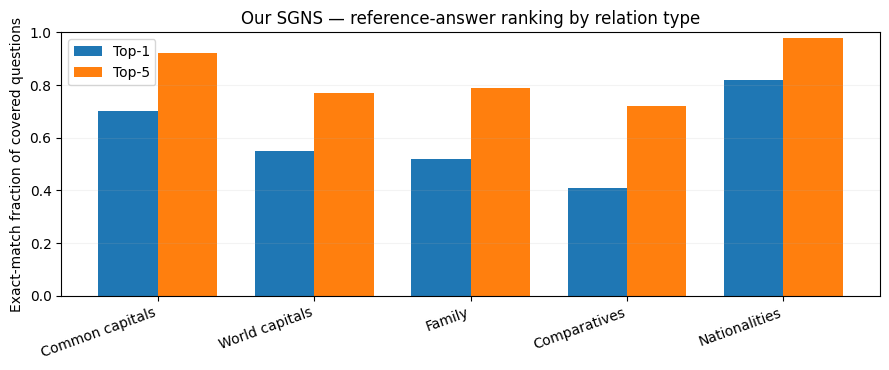

First top-1 failure in each category:


Category,Analogy,Expected,Predicted top-1,Expected rank
Common capitals,madrid:spain :: london:?,england,britain,2
World capitals,lima:peru :: rome:?,italy,constantinople,15
Family,king:queen :: husband:?,wife,her,7
Comparatives,bad:worse :: weak:?,weaker,stronger,2
Nationalities,norway:norwegian :: ukraine:?,ukrainian,russian,2


In [21]:
def diagnose_analogies(question_sets, vectors, w2i, idx2word, k=5):
    """Fast batch evaluator: same normalized 3CosAdd rule as the student's analogy()."""
    E = F.normalize(vectors.float(), dim=1, eps=1e-12)
    rows = []
    for category, qs in question_sets.items():
        if not qs:
            continue
        ids = torch.tensor([[w2i[w] for w in q] for q in qs], dtype=torch.long)
        src, targets = ids[:, :3], ids[:, 3]
        queries = F.normalize(E[src[:, 1]] - E[src[:, 0]] + E[src[:, 2]], dim=1)
        sims = queries @ E.T
        ridx = torch.arange(len(qs))
        for j in range(3):
            sims[ridx, src[:, j]] = -float('inf')
        top = sims.topk(min(k, len(idx2word)-3), dim=1).indices
        target_sim = sims[ridx, targets]
        ranks = 1 + (sims > target_sim[:, None]).sum(dim=1)
        for i, words in enumerate(qs):
            rows.append({
                'category': category, 'question_id': i,
                'analogy': f'{words[0]}:{words[1]} :: {words[2]}:?',
                'target': words[3], 'top1': idx2word[int(top[i, 0])],
                'top5_hit': bool((top[i] == targets[i]).any()),
                'target_rank': int(ranks[i]),
            })
    return pd.DataFrame(rows)

sgns_diag = diagnose_analogies(questions, E_mine_sh, sh_w2i, shared)

def test_analogy_evaluator_consistency():
    """Ensure student's 3CosAdd function and the batch evaluation have identical top-1 predictions."""
    checks = 0
    for category, qs in questions.items():
        for i, (a, b, c, expected) in enumerate(qs[:3]):
            direct = analogy(a, b, c, E_mine_sh, sh_w2i, shared, k=5)
            batch_pred = sgns_diag.loc[
                (sgns_diag.category == category) & (sgns_diag.question_id == i), 'top1'
            ].iloc[0]
            assert direct[0][0] == batch_pred, (
                f'Analogy/batch evaluator disagree on {a}:{b}::{c}:?')
            checks += 1
    assert checks > 0
    return checks

n_parity = test_analogy_evaluator_consistency()
print(f'✓ Student 3CosAdd agrees with batch evaluation on {n_parity} real questions.')

summary_c = (sgns_diag.assign(top1_hit=sgns_diag.top1.eq(sgns_diag.target))
             .groupby('category', sort=False)
             .agg(n=('top1_hit', 'size'), top1=('top1_hit', 'mean'),
                  top5=('top5_hit', 'mean'), median_target_rank=('target_rank', 'median'))
             .reset_index())
label_map = {
    'capital-common-countries': 'Common capitals',
    'capital-world': 'World capitals',
    'family': 'Family',
    'gram3-comparative': 'Comparatives',
    'gram6-nationality-adjective': 'Nationalities',
}
summary_c['Category'] = summary_c.category.map(label_map).fillna(summary_c.category)
print('Our SGNS — analogy ranking (same fixed covered questions for both Top-1 and Top-5):')
display(summary_c[['Category','n','top1','top5','median_target_rank']]
        .rename(columns={'n':'Questions','top1':'Top-1','top5':'Top-5',
                         'median_target_rank':'Median target rank'})
        .style.format({'Top-1':'{:.0%}','Top-5':'{:.0%}',
                       'Median target rank':'{:.0f}'}).hide(axis='index'))

x = np.arange(len(summary_c))
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(x - .19, summary_c.top1, width=.38, label='Top-1')
ax.bar(x + .19, summary_c.top5, width=.38, label='Top-5')
ax.set_xticks(x, summary_c['Category'], rotation=20, ha='right')
ax.set_ylim(0, 1)
ax.set_ylabel('Exact-match fraction of covered questions')
ax.set_title('Our SGNS — reference-answer ranking by relation type')
ax.legend()
ax.grid(axis='y', alpha=.15)
plt.tight_layout()
plt.show()

# Show the first incorrect top-1 prediction from each category.
failures = sgns_diag[sgns_diag.target_rank > 1].groupby('category', sort=False).head(1)
failures = failures.assign(Category=failures.category.map(label_map).fillna(failures.category))
print('First top-1 failure in each category:')
display(failures[['Category', 'analogy', 'target', 'top1', 'target_rank']]
        .rename(columns={'analogy': 'Analogy', 'target': 'Expected', 'top1': 'Predicted top-1',
                         'target_rank': 'Expected rank'})
        .style.hide(axis='index'))

### Experiment B2: What changes when we remove the offset?

The table compares three searches on the same questions:

1. **3CosAdd**, with the input words excluded.
2. **No offset**, using the nearest neighbor of `c` and still excluding the input words.
3. **3CosAdd without exclusions**, allowing `a`, `b`, or `c` to appear in the results.

Comparing the first two isolates the effect of the relationship offset. Comparing the first and third shows the effect of excluding the input words. The lines under the table give examples from the third setting.

In [22]:
def offset_ablation(question_sets, vectors, w2i):
    """Top-1 accuracy of three variants of the analogy search, per category."""
    En = F.normalize(vectors.float(), dim=1, eps=1e-12)
    rows = []
    for category, qs in question_sets.items():
        ids = torch.tensor([[w2i[w] for w in q] for q in qs], dtype=torch.long)
        a, b, c, d = ids[:, 0], ids[:, 1], ids[:, 2], ids[:, 3]
        row_ids = torch.arange(len(qs))

        def top1(query, exclude):
            sims = F.normalize(query, dim=1, eps=1e-12) @ En.T
            for ex in exclude:
                sims[row_ids, ex] = -float('inf')
            return sims.argmax(dim=1)

        offset = En[b] - En[a] + En[c]
        rows.append({
            'Category': label_map.get(category, category),
            '3CosAdd': (top1(offset, [a, b, c]) == d).float().mean().item(),
            'No offset (nearest to c)': (top1(En[c], [a, b, c]) == d).float().mean().item(),
            '3CosAdd, nothing excluded': (top1(offset, []) == d).float().mean().item(),
        })
    return pd.DataFrame(rows)

ablation = offset_ablation(questions, E_mine_sh, sh_w2i)
display(ablation.style.format({col: '{:.0%}' for col in ablation.columns[1:]}).hide(axis='index'))

En_sh = F.normalize(E_mine_sh, dim=1)
for category, qs in questions.items():
    a_, b_, c_, d_ = qs[0]
    q_ = En_sh[sh_w2i[b_]] - En_sh[sh_w2i[a_]] + En_sh[sh_w2i[c_]]
    print(f'{a_}:{b_} :: {c_}:?  expected {d_:12s} top-1 with nothing excluded: {shared[int((En_sh @ q_).argmax())]}')

Category,3CosAdd,No offset (nearest to c),"3CosAdd, nothing excluded"
Common capitals,70%,21%,8%
World capitals,55%,21%,13%
Family,52%,24%,7%
Comparatives,41%,5%,3%
Nationalities,82%,2%,36%


madrid:spain :: london:?  expected england      top-1 with nothing excluded: london
lima:peru :: rome:?  expected italy        top-1 with nothing excluded: rome
king:queen :: husband:?  expected wife         top-1 with nothing excluded: husband
high:higher :: bright:?  expected brighter     top-1 with nothing excluded: bright
germany:german :: cambodia:?  expected cambodian    top-1 with nothing excluded: cambodia
